# Tumor-edge：CCC 主任务与基因表达联合重构

选择 **cccphe**，执行 **Restart Kernel → Run All**。复用同一份 8,000-cell 模拟数据和 NMF 初始化的 CCC 预训练模型；联合阶段让基因表达损失参与更新 GNN/Z，H 只由 CCC 更新。表达梯度冲突投影且范数不超过 CCC 梯度的 10%；验证 CCC 相对预训练最多允许 0.5% 波动，再选择表达验证损失最小的合格 checkpoint。若没有合格改进，保留基线并如实标注。结果独立存入 NAS，不覆盖旧模型。

表达标签是**微环境内各细胞类型的空间加权表达**，缺失类型不监督；包含 24 个由实际 LR 信号驱动的模拟响应基因与 12 个阴性对照，均不进入编码器。它们是模拟基因，不称为真实上游调控因子或通路。

In [1]:
%matplotlib inline
from pathlib import Path
import sys,contextlib
import matplotlib.pyplot as plt
import torch
from IPython.display import display
ROOT=Path('/home/xueshuailin/CCC_Phe')
sys.path.insert(0,str(ROOT/'src'))
from phenoniche.simulation.dependencies import prepare_environment
from phenoniche.simulation.response_simulation import ExpressionExperimentConfig
from phenoniche.simulation.response_experiment import run_expression_experiment
from phenoniche.simulation.joint_reporting import JointExpressionReport
from phenoniche.training import set_seed
config=ExpressionExperimentConfig.from_json(ROOT/'config/tumor_edge_expression.json')
OUTPUT=Path(config.output_dir)
OUTPUT.mkdir(parents=True,exist_ok=True)
torch.set_num_threads(6)
set_seed(config.seed)
if config.device.startswith('cuda:') and not torch.cuda.is_available():
    raise RuntimeError('请在服务器 cccphe GPU 环境中运行')
with (OUTPUT/'notebook_execution.log').open('a',buffering=1) as log,contextlib.redirect_stdout(log),contextlib.redirect_stderr(log):
    prepare_environment()
    run_expression_experiment(config)
report=JointExpressionReport(OUTPUT)
def show(fig):
    display(fig)
    plt.close(fig)

## 1. 模拟组织与模型 niche

显示原始聚类编号，不用真实标签替换模型输出。CCC-only 与联合模型使用相同数据，联合模型 K=4–15 的选择只用训练/验证集，不读取真实 niche。

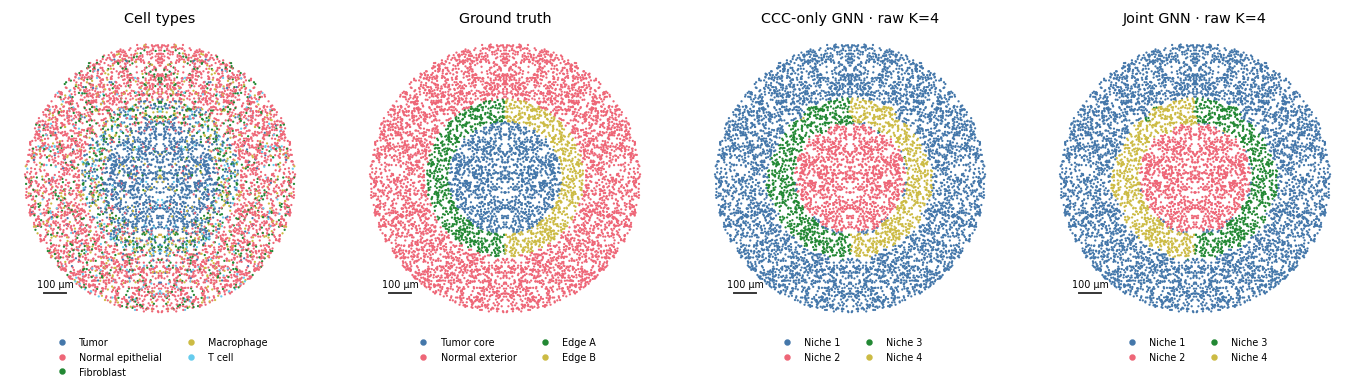

In [2]:
show(report.spatial_comparison())

## 2. 四个真实通讯程序是否恢复

上下两行使用相同数值尺度；下方由 **Z @ H** 沿预先定义的 MI 字典投影，汇总全部 32 个程序的贡献，不强制一个 MI 对应一个 Z 维度。真实字典只用于训练后的评估。

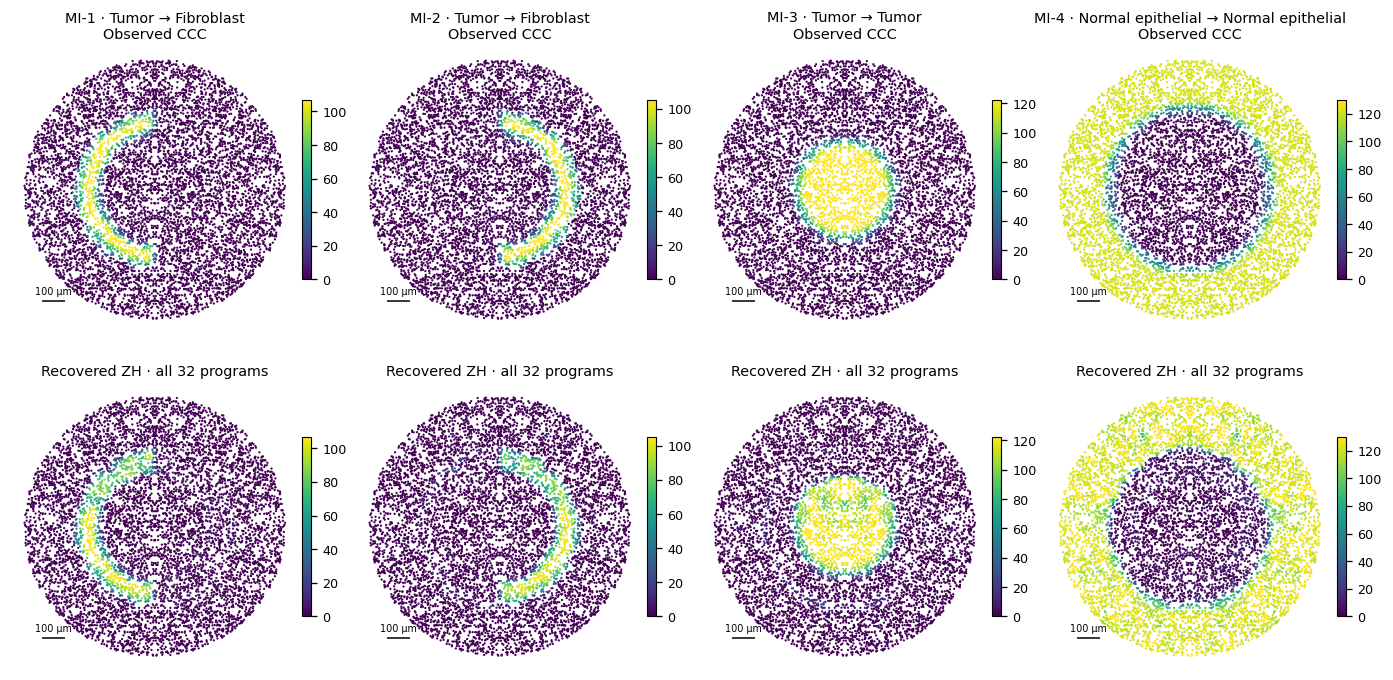

In [3]:
show(report.communication_recovery())

## 3. 基因表达是否对应

同一列是同一个模拟响应基因；每个 niche 内按该基因的 receiver 类型汇总空间加权表达，再减去该类型中这个基因的观测均值。上下两幅共用色标和参考均值，蓝色较低、红色较高。热图展示**全组织（含训练和验证中心）的描述性结果**。下方另用空间测试集对比基线、冻结版和联合版的 RMSE，并显示测试覆盖；严格两跳划分后没有肿瘤核心测试中心，因此不能宣称核心区基因恢复已获独立验证。

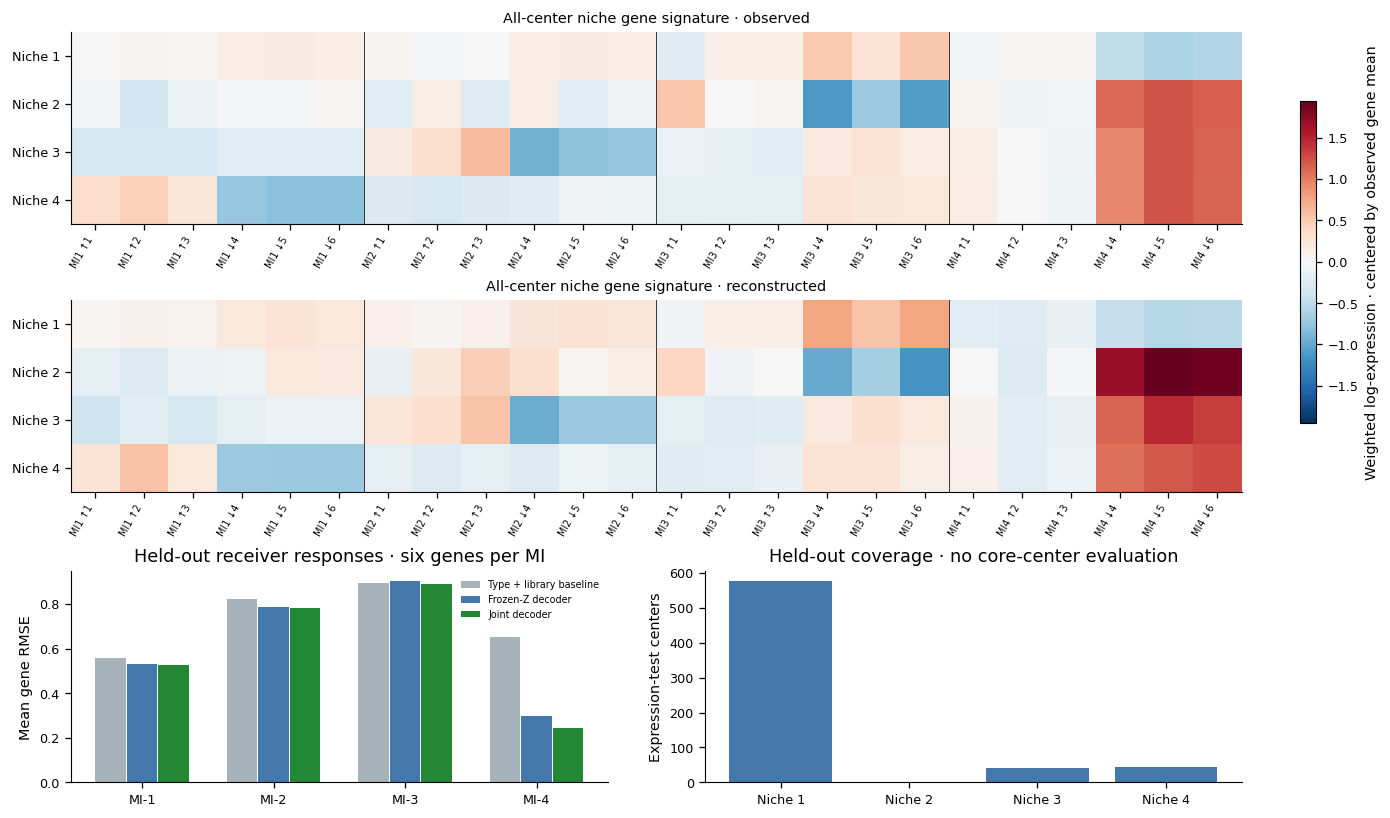

In [4]:
show(report.expression_recovery())

## 4. Niche 与细胞类型的关系

同一物理细胞对权重计算的空间加权组成。此图仅用于下游解释，不增加细胞组成重建损失。

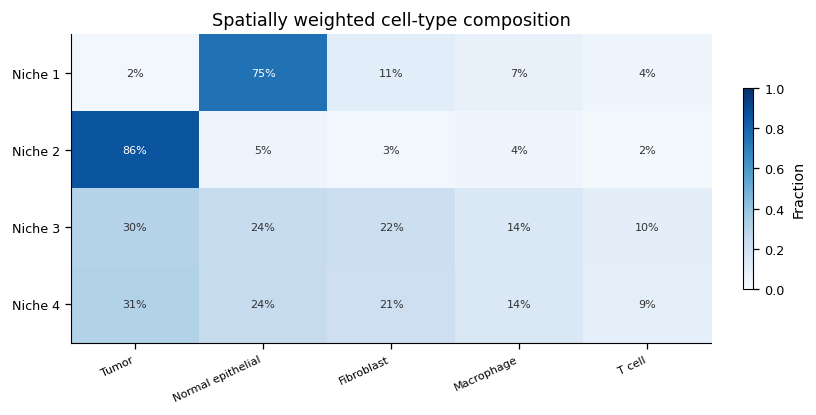

In [5]:
show(report.niche_cell_types())

## 5. 每个 niche 的 top10 CCC

对 niche 内 Z 取均值后乘 H：**mean(Z | niche) @ H**。表中列出 sender→receiver→LR、平均重构强度及贡献最大的程序；niche 可由多个程序共同形成。排序按原始 CCC 单位计算，不代表临床显著性或因果作用。

In [6]:
display(report.top_ccc.rename(columns={'niche':'Niche','rank':'Rank','sender':'Sender','receiver':'Receiver','LR':'Ligand–Receptor','mean_reconstructed_CCC':'Mean CCC','main_program':'Main program'}).drop(columns=['LR_id']).style.format({'Mean CCC':'{:.3f}'}).hide(axis='index'))

Niche,Rank,Sender,Receiver,Ligand–Receptor,Mean CCC,Main program
1,1,Normal epithelial,Normal epithelial,APOB–LRP6,19.733,1
1,2,Normal epithelial,Normal epithelial,CCL25–CCR10,19.725,1
1,3,Normal epithelial,Normal epithelial,COL4A2–DDR2,19.710,1
1,4,Normal epithelial,Normal epithelial,PLAT–ITGB2,19.692,1
1,5,Normal epithelial,Normal epithelial,TSHB–ADRB3,19.678,1
1,6,Normal epithelial,Normal epithelial,DSC1–DSG2,19.652,1
1,7,Normal epithelial,Normal epithelial,BMP10–BMPR1A,6.337,1
1,8,Normal epithelial,Normal epithelial,DEFB4A–CCR6,6.194,1
1,9,Normal epithelial,Normal epithelial,IAPP–RAMP1,6.168,1
1,10,Fibroblast,Fibroblast,BCAN–NRCAM,5.656,1


## 6. 训练 loss

分别显示 CCC 预训练和联合阶段的两个任务，数值尺度不同。虚线标出选中的 joint epoch，点线表示验证 CCC 的接受上限；epoch 0 是冻结版起点。

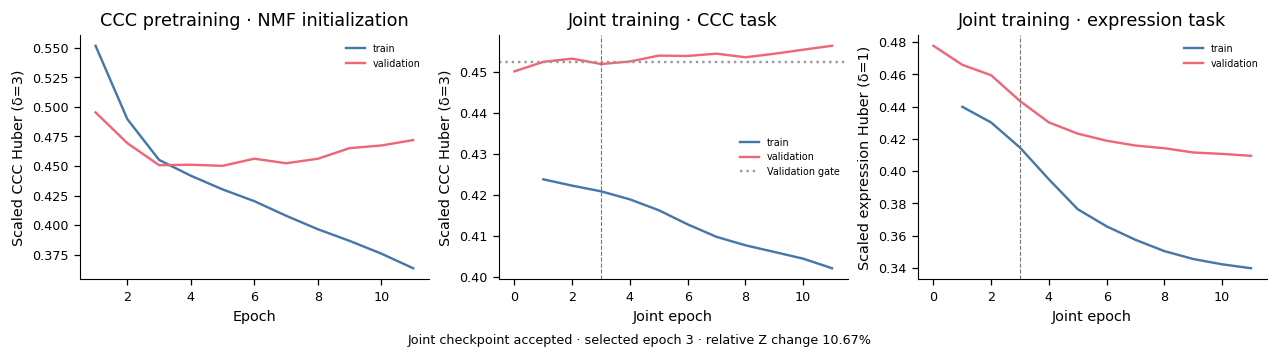

In [7]:
show(report.curves())

## 7. 模拟数据与模型结果总图

真实四区域、细胞类型、CCC-only 和联合 niche 并排显示；下方比较四个真实 MI 与恢复的通讯强度。**仅这张总图**使用训练中心拟合的标签颜色映射，便于直观对照；第一图和表中仍保留原始编号。底部指标由 held-out test 实际计算，标签匹配未进入训练或 K 选择。高分是本模拟、当前随机种子的结果，不是临床验证。全部 PNG/PDF/SVG、指标和模型数组在 NAS 输出目录。

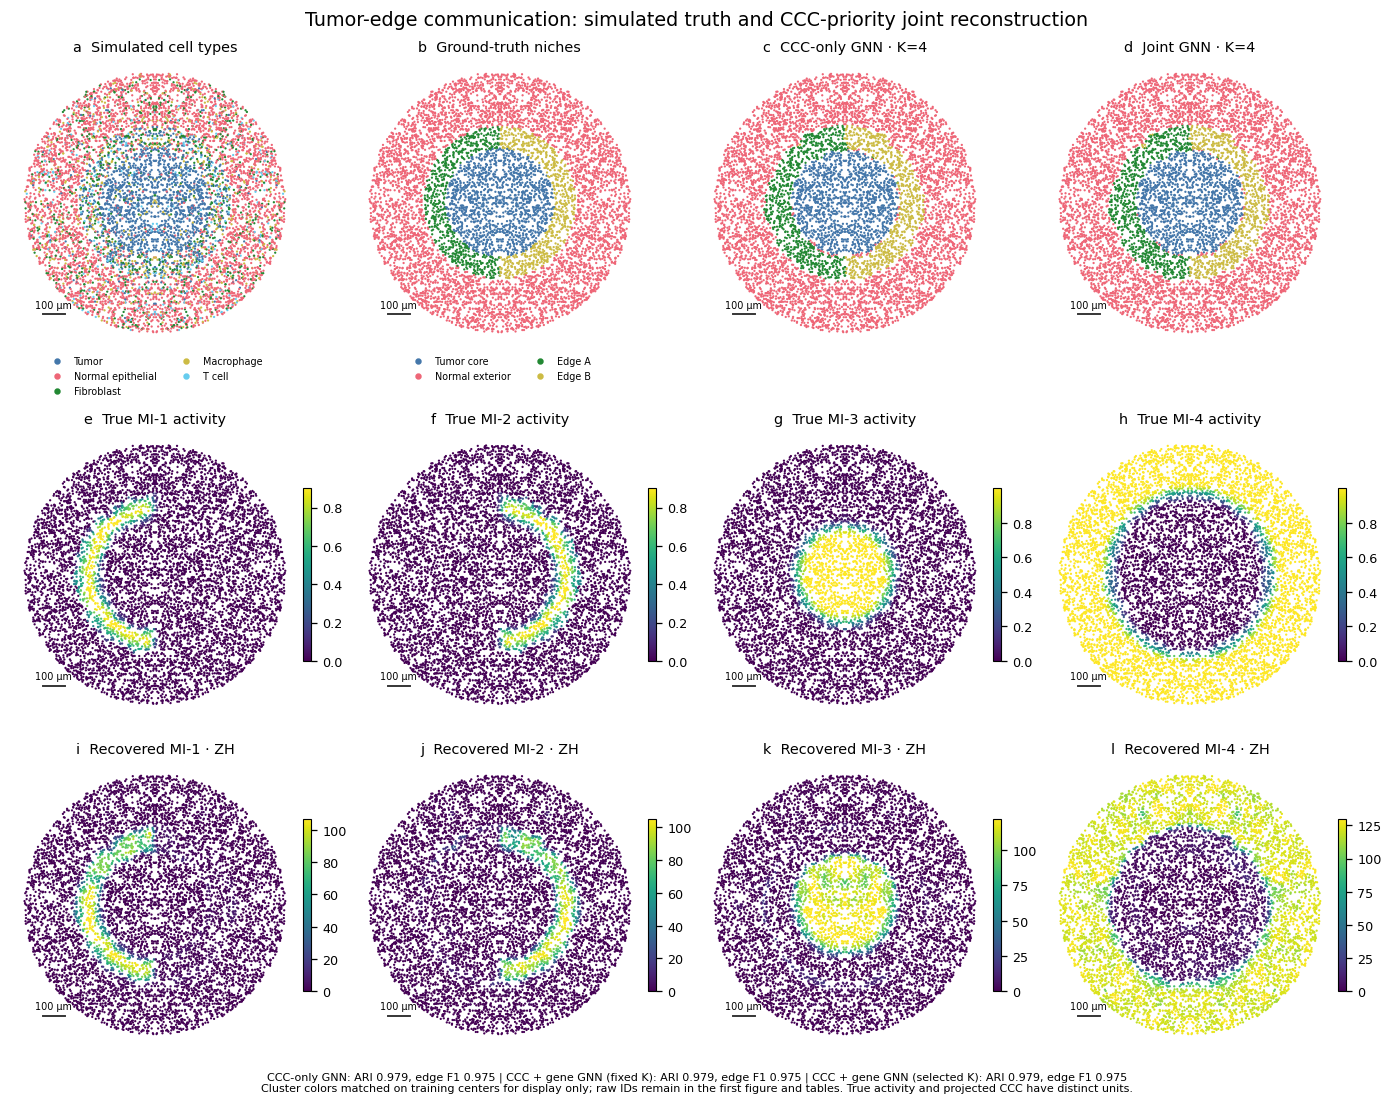

In [8]:
show(report.summary_figure())

## 8. 与空间聚类 baseline 比较

使用公开的 [GraphST](https://github.com/JinmiaoChenLab/GraphST) 和 [CellCharter](https://github.com/CSOgroup/cellcharter)。代码和配置位于项目 `baselines/`，结果存入当前 NAS 实验的 `baseline_comparison/`。

**比较协议：**同样的 8,000 个细胞和原始 256 个基因，新增响应/阴性对照基因不进入 baseline；同样的原始 KNN30 邻域拓扑。预处理、表示模型和聚类参数只在原 GNN 训练区域拟合，固定 K=4，不按真实标签选参数。GraphST 使用官方稀疏模型＋作者 `emb` 表示＋KMeans；CellCharter 使用 **PCA32＋一跳空间聚合＋官方 GMM**，明确是 PCA 变体，未声称使用 scVI。两者各自保留原方法的权重/归一化，并记录配置和运行时间。

CCC-AE 使用预计算 CCC；细胞组成方法使用类型标签；我们的 GNN 使用 CCC 与类型分层表达监督。其他表达/空间 baseline 不得到这些监督信息，因此这是一项**同数据、不同信息条件**的比较。现有 GNN checkpoint 不重训、不改参数。

In [9]:
sys.path.insert(0,str(ROOT))
from baselines.benchmark import run_comparison
from baselines.reporting import BaselineReport
with (OUTPUT/'baseline_comparison_execution.log').open('a',buffering=1) as log,contextlib.redirect_stdout(log),contextlib.redirect_stderr(log):
    BASELINE_OUTPUT=run_comparison(OUTPUT)
    baseline_report=BaselineReport(OUTPUT,BASELINE_OUTPUT)

### 空间聚类图

第一图保留各方法的原始 cluster ID；第二图仅为看图方便，用训练中心拟合颜色映射。真实标签均在拟合结束后才用于评价，不能把配色匹配当成预测。所有图含训练区域，下方 ARI 是全组织描述性恢复指标。

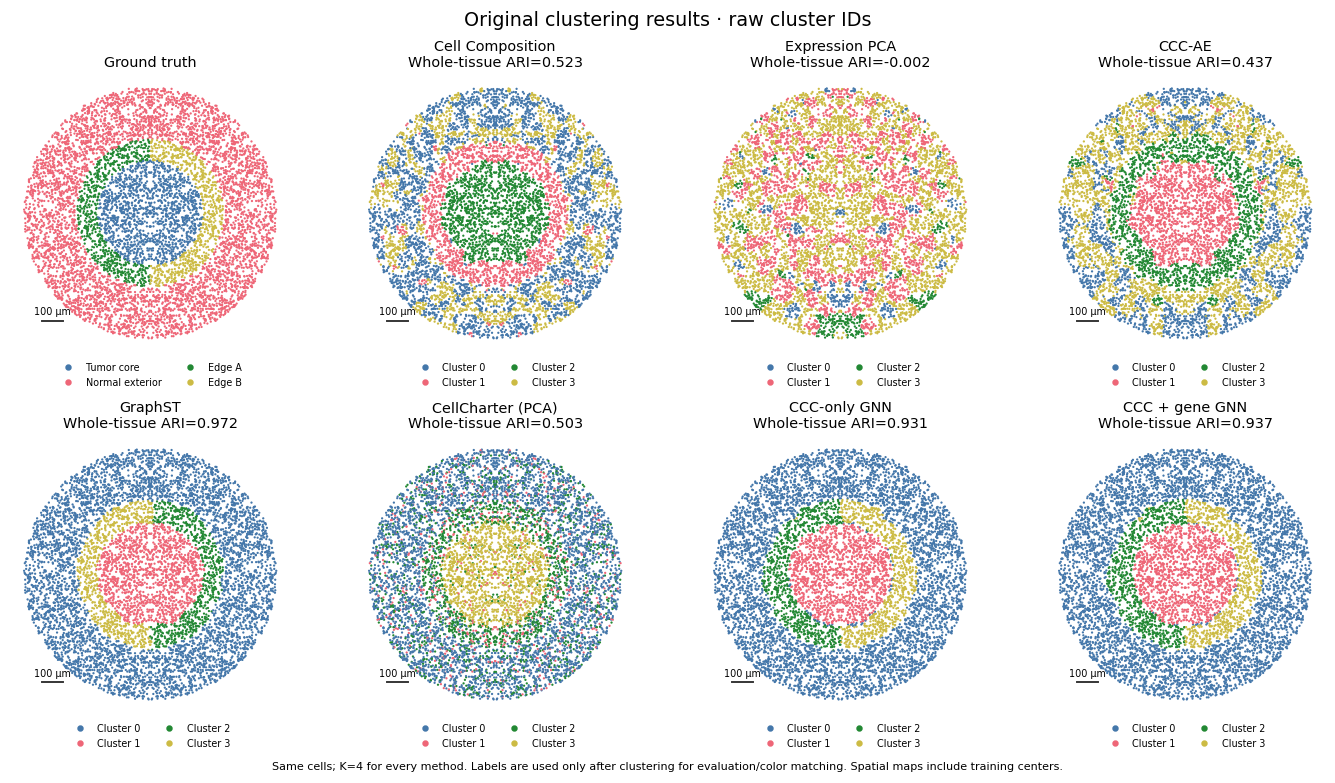

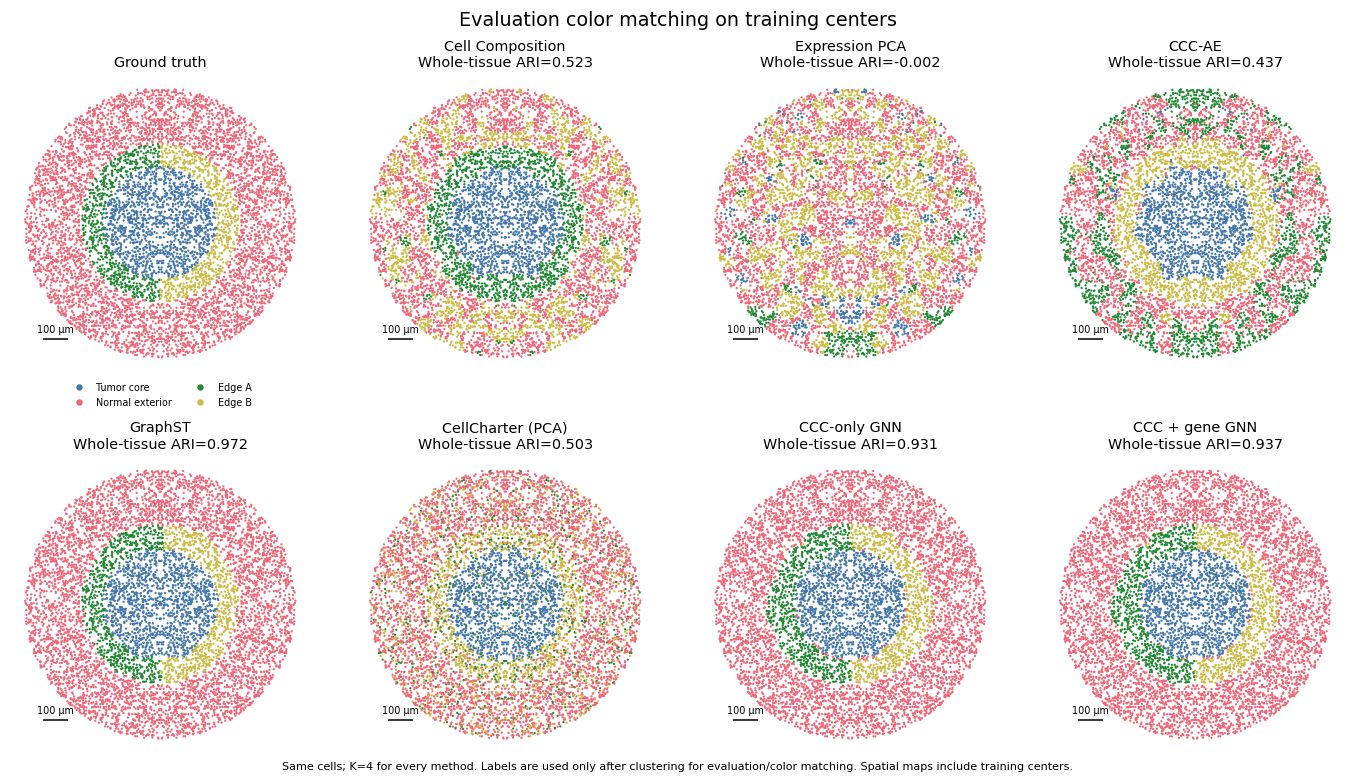

In [10]:
show(baseline_report.spatial(align=False))
show(baseline_report.spatial(align=True))

### 同一批空间测试中心上的评价

GraphST 的重构需要两跳图输入，因此所有方法统一使用原空间测试划分再加两跳隔离的中心集合。表中 `n`、`n_true_edge` 给出实际覆盖；未覆盖的区域不宣称已独立验证。ARI/NMI 使用原始聚类编号；F1/IoU 和 A/B accuracy 的映射只在训练中心拟合。固定 K=4 是预先定义的公平比较，不是无监督发现区域数的证据。当前只有一个模拟/训练随机种子，结果用于框架比较。

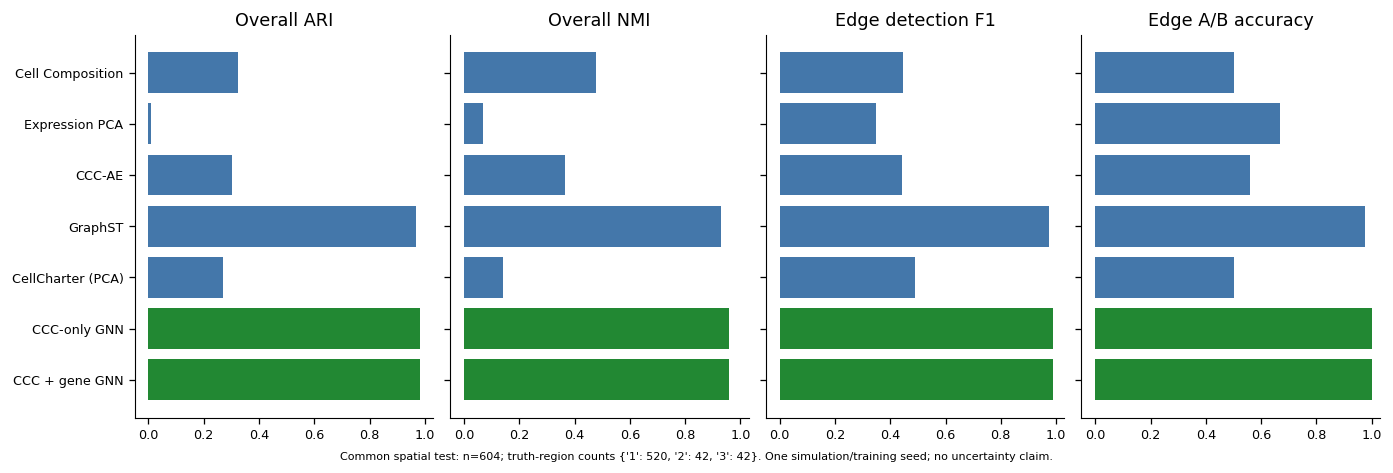

method,K,n,n_true_edge,overall_ARI,overall_NMI,edge_F1,edge_IoU,edge_AB_ARI,edge_AB_accuracy
Cell Composition,4,604,84,0.325,0.478,0.444,0.286,-0.002,0.500
Expression PCA,4,604,84,0.010,0.070,0.348,0.211,0.103,0.667
CCC-AE,4,604,84,0.301,0.366,0.444,0.285,0.008,0.560
CCC-only GNN,4,604,84,0.984,0.960,0.988,0.976,0.976,1.000
CCC + gene GNN,4,604,84,0.984,0.960,0.988,0.976,0.976,1.000
GraphST,4,604,84,0.967,0.929,0.976,0.952,0.906,0.976
CellCharter (PCA),4,604,84,0.271,0.141,0.489,0.324,-0.013,0.500
CellCharter (PCA; common KMeans),4,604,84,0.381,0.625,0.279,0.162,1.000,1.000


In [11]:
show(baseline_report.metric_plot())
display(baseline_report.metric_table().style.format({k:'{:.3f}' for k in ['overall_ARI','overall_NMI','edge_F1','edge_IoU','edge_AB_ARI','edge_AB_accuracy']}).hide(axis='index'))

### 全组织描述性指标与计算条件

此表补充包括核心区在内的全组织恢复效果，含训练中心，不能解释成独立泛化评估。空间 baseline 没有 directed CCC decoder，因此不编造其 CCC 重构指标。方法原始输出、checkpoint、输入基因、严格公共测试划分、软件版本和官方源码 commit 均保存在 NAS 中。

In [12]:
display(baseline_report.metrics.query("scope == 'all_centers_descriptive'")[['method','K','n','overall_ARI','overall_NMI','edge_F1','edge_AB_accuracy']].style.format({k:'{:.3f}' for k in ['overall_ARI','overall_NMI','edge_F1','edge_AB_accuracy']}).hide(axis='index'))

method,K,n,overall_ARI,overall_NMI,edge_F1,edge_AB_accuracy
Cell Composition,4,8000,0.523,0.640,0.564,0.500
Expression PCA,4,8000,-0.002,0.036,0.358,0.543
CCC-AE,4,8000,0.437,0.568,0.516,0.528
CCC-only GNN,4,8000,0.931,0.869,0.940,0.988
CCC + gene GNN,4,8000,0.937,0.880,0.938,0.993
GraphST,4,8000,0.972,0.919,0.963,0.975
CellCharter (PCA),4,8000,0.503,0.449,0.573,0.500
CellCharter (PCA; common KMeans),4,8000,0.501,0.680,0.327,0.992
